# Northern Virginia (NOVA) — Population Demographics Analysis
**Prepared by:** Parity Insights LLC | **Purpose:** Retail Site Selection & Customer Profiling

---

## Research Questions

1. What are the gender and age dynamics across NOVA counties — who is the primary customer profile?
2. What are the income dynamics by age group across each county?
3. What is the language diversity landscape, and what are the implications for marketing strategy?

---

**Data:** U.S. Census Bureau, American Community Survey (ACS) 1-Year Estimates, 2025
**Counties:** Arlington, Fairfax, Fauquier, Loudoun, Prince William

In [ ]:
# Standard data analysis and visualization libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Section 1 — Female Population Demographics by Age Group

**Objective:** Identify the size and age distribution of the primary target demographic (females, ages 20–59) across NOVA counties.

**Source:** ACS Table S0101 — Age and Sex (1-Year Estimates, 2025)

In [ ]:
# Load ACS S0101 population data; first data row contains descriptive column labels
population_nova = pd.read_csv("/content/ACSST1Y2025.S0101-Data.csv")

# Promote first row to column headers (ACS CSV format includes a label row)
population_nova.columns = population_nova.iloc[0]

# Drop margin-of-error columns — analysis uses point estimates only
population_nova = population_nova.loc[
    :, ~population_nova.columns.str.startswith("Margin of Error", na=False)
]

population_nova.head()

In [ ]:
# Inspect all available column names after cleaning
population_nova.columns.tolist()

In [ ]:
# Target demographic: females aged 20–59 (primary retail customer profile)
target_columns = [
    "Estimate!!Total!!Total population",
    "Estimate!!Percent Female!!Total population!!AGE!!20 to 24 years",
    "Estimate!!Percent Female!!Total population!!AGE!!25 to 29 years",
    "Estimate!!Percent Female!!Total population!!AGE!!30 to 34 years",
    "Estimate!!Percent Female!!Total population!!AGE!!35 to 39 years",
    "Estimate!!Percent Female!!Total population!!AGE!!40 to 44 years",
    "Estimate!!Percent Female!!Total population!!AGE!!45 to 49 years",
    "Estimate!!Percent Female!!Total population!!AGE!!50 to 54 years",
    "Estimate!!Percent Female!!Total population!!AGE!!55 to 59 years",
]

nova_target_females = population_nova[target_columns].copy()
nova_target_females

In [ ]:
# -----------------------------------------------------------------
# 1. Column definitions — include county name for downstream filters
# -----------------------------------------------------------------
geo_col = "Geographic Area Name"
total_pop_col = "Estimate!!Total!!Total population"

pct_age_columns = [
    "Estimate!!Percent Female!!Total population!!AGE!!20 to 24 years",
    "Estimate!!Percent Female!!Total population!!AGE!!25 to 29 years",
    "Estimate!!Percent Female!!Total population!!AGE!!30 to 34 years",
    "Estimate!!Percent Female!!Total population!!AGE!!35 to 39 years",
    "Estimate!!Percent Female!!Total population!!AGE!!40 to 44 years",
    "Estimate!!Percent Female!!Total population!!AGE!!45 to 49 years",
    "Estimate!!Percent Female!!Total population!!AGE!!50 to 54 years",
    "Estimate!!Percent Female!!Total population!!AGE!!55 to 59 years",
]

nova_target_females = population_nova[[geo_col, total_pop_col] + pct_age_columns].copy()

# -----------------------------------------------------------------
# 2. Convert demographic values to numeric
# -----------------------------------------------------------------
nova_target_females[total_pop_col] = pd.to_numeric(
    nova_target_females[total_pop_col], errors="coerce"
)
nova_target_females[pct_age_columns] = nova_target_females[pct_age_columns].apply(
    pd.to_numeric, errors="coerce"
)

# -----------------------------------------------------------------
# 3. Derive headcount columns from percentage × total population
# -----------------------------------------------------------------
count_columns = [col.replace("Percent Female", "Count Female") for col in pct_age_columns]

for pct_col, count_col in zip(pct_age_columns, count_columns):
    nova_target_females[count_col] = (
        (nova_target_females[pct_col] / 100.0) * nova_target_females[total_pop_col]
    ).round()

# -----------------------------------------------------------------
# 4. Arlington County — target female age distribution
# -----------------------------------------------------------------
arlington = nova_target_females[
    nova_target_females[geo_col].str.contains("Arlington", case=False, na=False)
]

values = arlington[count_columns].iloc[0]
labels = [col.split("!!")[-1] for col in pct_age_columns]

plt.figure(figsize=(9, 9))
plt.pie(values, labels=labels, autopct="%1.1f%%", startangle=140)
plt.title(
    "Female Target Demographic (Ages 20–59)\nArlington County, VA",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

In [ ]:
# Fairfax County — target female age distribution
fairfax = nova_target_females[
    nova_target_females[geo_col].str.contains("Fairfax", case=False, na=False)
]

values = fairfax[count_columns].iloc[0]
labels = [col.split("!!")[-1] for col in pct_age_columns]

plt.figure(figsize=(9, 9))
plt.pie(values, labels=labels, autopct="%1.1f%%", startangle=140)
plt.title(
    "Female Target Demographic (Ages 20–59)\nFairfax County, VA",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

In [ ]:
# Prince William County — target female age distribution
prince_william = nova_target_females[
    nova_target_females[geo_col].str.contains("Prince William", case=False, na=False)
]

values = prince_william[count_columns].iloc[0]
labels = [col.split("!!")[-1] for col in pct_age_columns]

plt.figure(figsize=(9, 9))
plt.pie(values, labels=labels, autopct="%1.1f%%", startangle=140)
plt.title(
    "Female Target Demographic (Ages 20–59)\nPrince William County, VA",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

In [ ]:
# Fauquier County — target female age distribution
fauquier = nova_target_females[
    nova_target_females[geo_col].str.contains("Fauquier", case=False, na=False)
]

values = fauquier[count_columns].iloc[0]
labels = [col.split("!!")[-1] for col in pct_age_columns]

plt.figure(figsize=(9, 9))
plt.pie(values, labels=labels, autopct="%1.1f%%", startangle=140)
plt.title(
    "Female Target Demographic (Ages 20–59)\nFauquier County, VA",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

### Section 1 — Key Findings: Female Target Demographic (Ages 20–59)

Across NOVA counties, the female 20–59 cohort is broadly distributed with no single age band dominating, indicating a stable and multi-generational customer base throughout prime spending years.

| County | Profile |
|---|---|
| **Arlington** | Skews younger (20–34), reflecting its dense urban character and high concentration of young professionals |
| **Fairfax** | Largest absolute headcount of any county; well-balanced distribution centered on 35–49 — the highest-spend cohort |
| **Prince William** | Highest proportional share of 35–44 females; a suburban family-formation demographic with strong retail affinity |
| **Fauquier** | Smallest total population; skews older (45–59), reflecting a rural profile with limited retail density |

**Conclusion:** Fairfax County offers the largest total addressable market of target-age females with the most favorable age-band balance for retail conversion.

2. Income Demographics by age in NOVA

In [ ]:
income_nova = pd.read_csv("/content/income.S1903-Data.csv")
income_nova

,GEO_ID,NAME,S1903_C01_001E,S1903_C01_001M,S1903_C01_002E,S1903_C01_002M,S1903_C01_003E,S1903_C01_003M,S1903_C01_004E,S1903_C01_004M,...,S1903_C03_036M,S1903_C03_037E,S1903_C03_037M,S1903_C03_038E,S1903_C03_038M,S1903_C03_039E,S1903_C03_039M,S1903_C03_040E,S1903_C03_040M,Unnamed: 242
0,Geography,Geographic Area Name,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND...,Margin of Error!!Number!!HOUSEHOLD INCOME BY R...,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND...,Margin of Error!!Number!!HOUSEHOLD INCOME BY R...,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND...,Margin of Error!!Number!!HOUSEHOLD INCOME BY R...,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND...,Margin of Error!!Number!!HOUSEHOLD INCOME BY R...,...,Margin of Error!!Median income (dollars)!!NONF...,Estimate!!Median income (dollars)!!NONFAMILY H...,Margin of Error!!Median income (dollars)!!NONF...,Estimate!!Median income (dollars)!!NONFAMILY H...,Margin of Error!!Median income (dollars)!!NONF...,Estimate!!Median income (dollars)!!NONFAMILY H...,Margin of Error!!Median income (dollars)!!NONF...,Estimate!!Median income (dollars)!!NONFAMILY H...,Margin of Error!!Median income (dollars)!!NONF...,NaN
1,0500000US51013,"Arlington County, Virginia",113687,2825,71404,2599,10008,1253,N,N,...,7363,182442,17484,123109,4334,114480,7369,166906,24893,NaN
2,0500000US51059,"Fairfax County, Virginia",421189,2612,225482,4163,40509,2606,N,N,...,6601,153370,22392,111232,6621,98072,7008,167961,21727,NaN
3,0500000US51061,"Fauquier County, Virginia",27882,820,22108,896,N,N,N,N,...,12266,103979,43535,98724,36771,80633,15782,148935,33162,NaN
4,0500000US51107,"Loudoun County, Virginia",150062,1528,84389,2690,N,N,N,N,...,14870,180512,91157,130052,28449,111248,27405,162389,59153,NaN
5,0500000US51153,"Prince William County, Virginia",161049,1596,76979,2441,34091,2155,N,N,...,5665,114631,59241,101630,12397,100020,10044,139521,38591,NaN


In [ ]:
#Clean the data, remove margin of error data
income_nova.columns = income_nova.iloc[0]

nova_income_cleaned = income_nova.iloc[1:].loc[:,~income_nova.columns.str.startswith("Margin of Error",na= False)].reset_index(drop=True)
nova_income_cleaned.head()

,Geography,Geographic Area Name,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!White,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Black or African American,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!American Indian and Alaska Native,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Asian,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Native Hawaiian and Other Pacific Islander,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Some other race,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!Two or more races,...,Estimate!!Median income (dollars)!!FAMILY INCOME BY NUMBER OF EARNERS!!2 earners,Estimate!!Median income (dollars)!!FAMILY INCOME BY NUMBER OF EARNERS!!3 or more earners,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Female householder,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Female householder!!Living alone,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Female householder!!Not living alone,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Male householder,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Male householder!!Living alone,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Male householder!!Not living alone,NaN
0,0500000US51013,"Arlington County, Virginia",113687,71404,10008,N,14207,N,N,N,...,249553,"250,000+",111000,95479,88848,182442,123109,114480,166906,NaN
1,0500000US51059,"Fairfax County, Virginia",421189,225482,40509,N,85575,N,20360,46587,...,224481,246016,104547,100940,89130,153370,111232,98072,167961,NaN
2,0500000US51061,"Fauquier County, Virginia",27882,22108,N,N,N,N,N,N,...,153854,246171,78679,63641,53256,103979,98724,80633,148935,NaN
3,0500000US51107,"Loudoun County, Virginia",150062,84389,N,N,N,N,N,N,...,237379,"250,000+",100129,81038,67915,180512,130052,111248,162389,NaN
4,0500000US51153,"Prince William County, Virginia",161049,76979,34091,N,N,N,N,N,...,179730,232183,99381,80876,74975,114631,101630,100020,139521,NaN


In [ ]:
# Column list to get target columns
nova_income_cleaned.columns.to_list()

target_income_columns = [
    "Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!15 to 24 years",
    "Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!25 to 44 years",
    "Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!45 to 64 years",
]

In [ ]:
# New df with target income demographics

county_location = "Geographic Area Name"

nova_income_target = nova_income_cleaned[
    [county_location] + target_income_columns
].copy()

# Covert to numeric

for col in target_income_columns:
  nova_income_target[col] = pd.to_numeric(
      nova_income_target[col].astype(str).str.replace(",",""),errors = "coerce",
  )
nova_income_target.head()

,Geographic Area Name,Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!15 to 24 years,Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!25 to 44 years,Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!45 to 64 years
0,"Arlington County, Virginia",70967,126988,203754
1,"Fairfax County, Virginia",71756,161948,189772
2,"Fauquier County, Virginia",118590,136034,187075
3,"Loudoun County, Virginia",52997,205596,215139
4,"Prince William County, Virginia",87145,145367,168086


In [ ]:
# Plot the target demographics for better visualization

df_plot_income = nova_income_target.copy()

df_plot_income["Region"] = (
    df_plot_income["Geographic Area Name"].str.replace("County, Virginia", "",regex = False)
    .str.replace(", Virginia","",regex = False)
)

df_plot_clean_var = pd.melt(
    df_plot_income,
    id_vars = ["Region"],
    value_vars = target_income_columns,
    var_name = "Age Group",
    value_name = "Median Income",
)

df_plot_clean_var["Age Group"] = df_plot_clean_var["Age Group"].apply(
    lambda x:x.split("!!")[-1].replace(" years","")
)

df_plot_clean_var["Median Income"] = pd.to_numeric(df_plot_clean_var["Median Income"],errors = "coerce")
df_plot_clean_var.head()

,Region,Age Group,Median Income
0,Arlington,15 to 24,70967
1,Fairfax,15 to 24,71756
2,Fauquier,15 to 24,118590
3,Loudoun,15 to 24,52997
4,Prince William,15 to 24,87145


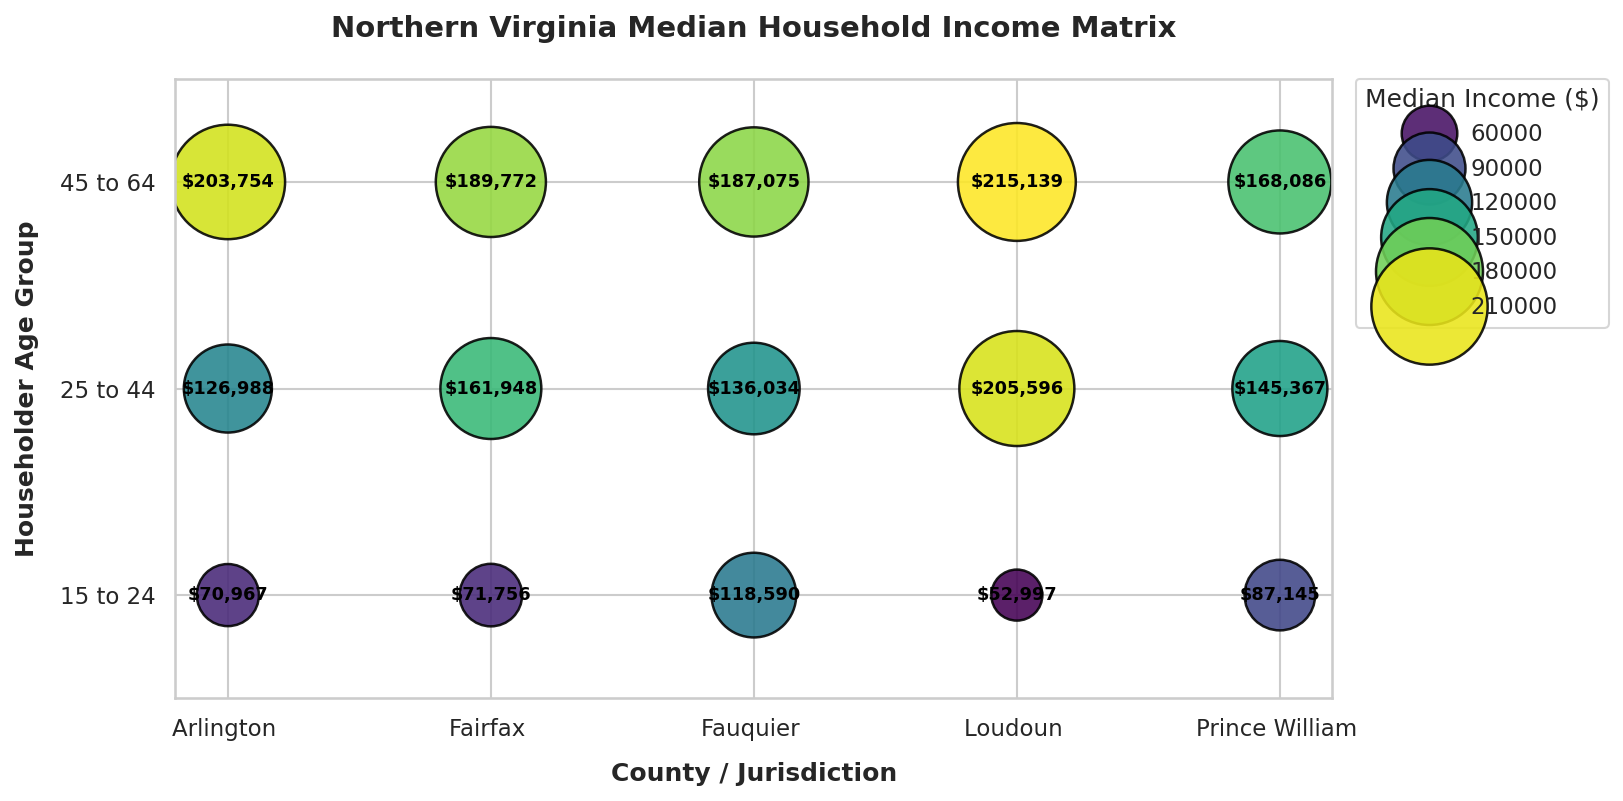

In [ ]:
# Plot

sns.set_theme(style="whitegrid")
fig,ax = plt.subplots(figsize = (11,5.5),dpi = 150)

scatter = sns.scatterplot(
    data = df_plot_clean_var,
    x = "Region",
    y = "Age Group",
    size = "Median Income",
    hue = "Median Income",
    palette = "viridis",
    sizes = (600,3200),
    edgecolor="black",
    linewidth=1.2,
    alpha=0.88,
    ax=ax,
)

# Add the exact Median Income in each bubble

for _,row in df_plot_clean_var.iterrows():
  if pd.notna(row["Median Income"]):
    ax.text(
        x = row["Region"],
        y = row["Age Group"],
        s = f"${int(row["Median Income"]):,}",
        ha="center",
              va="center",
              fontsize=8.5,
              fontweight="bold",
              color="black",
  )

# Polish Titles and Axes
plt.title(
    "Northern Virginia Median Household Income Matrix",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("County / Jurisdiction", fontweight="bold", labelpad=10)
plt.ylabel("Householder Age Group", fontweight="bold", labelpad=10)
ax.set_ylim(-0.5, 2.5)  # Add breathing room for top and bottom bubbles

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
    title="Median Income ($)",
)

plt.tight_layout()
plt.show()

I would recommend Fairfax county as the optimal county for the second store:
Reasons:


*   Balanced female demographics by age group
*   Prime target -> 25-44 years old income is second highest after Loudon County

*   Loudon County is not considered since its more rural and considering the commute, not ideal for Client







3. Spoken Language Demographics in NOVA

In [ ]:
spoken_language_df = pd.read_csv("/content/spoken_language.S1602-Data.csv")
spoken_language_df

,GEO_ID,NAME,S1602_C01_001E,S1602_C01_001M,S1602_C01_002E,S1602_C01_002M,S1602_C01_003E,S1602_C01_003M,S1602_C01_004E,S1602_C01_004M,...,S1602_C04_001M,S1602_C04_002E,S1602_C04_002M,S1602_C04_003E,S1602_C04_003M,S1602_C04_004E,S1602_C04_004M,S1602_C04_005E,S1602_C04_005M,Unnamed: 42
0,Geography,Geographic Area Name,Estimate!!Total!!All households,Margin of Error!!Total!!All households,Estimate!!Total!!All households!!Households sp...,Margin of Error!!Total!!All households!!Househ...,Estimate!!Total!!All households!!Households sp...,Margin of Error!!Total!!All households!!Househ...,Estimate!!Total!!All households!!Households sp...,Margin of Error!!Total!!All households!!Househ...,...,Margin of Error!!Percent limited English-speak...,Estimate!!Percent limited English-speaking hou...,Margin of Error!!Percent limited English-speak...,Estimate!!Percent limited English-speaking hou...,Margin of Error!!Percent limited English-speak...,Estimate!!Percent limited English-speaking hou...,Margin of Error!!Percent limited English-speak...,Estimate!!Percent limited English-speaking hou...,Margin of Error!!Percent limited English-speak...,NaN
1,0500000US51013,"Arlington County, Virginia",113687,2825,12733,1753,11786,2153,6903,1201,...,1.5,24.7,8.8,6.1,3.5,22.0,8.5,24.4,14.2,NaN
2,0500000US51059,"Fairfax County, Virginia",421189,2612,53066,2967,43217,3442,60213,3588,...,0.6,15.6,3.3,8.3,2.2,17.4,3.0,9.7,5.2,NaN
3,0500000US51061,"Fauquier County, Virginia",N,N,N,N,N,N,N,N,...,N,N,N,N,N,N,N,N,N,NaN
4,0500000US51107,"Loudoun County, Virginia",150062,1528,16040,1705,21726,2753,18363,2049,...,0.8,12.1,5.4,4.2,2.4,5.9,2.7,7.7,5.9,NaN
5,0500000US51153,"Prince William County, Virginia",161049,1596,32644,2124,13235,2178,10563,1934,...,1.1,10.4,3.7,12.3,6.4,12.3,5.4,8.5,6.6,NaN


In [ ]:
# Clean the data frame

# nova_income_cleaned = income_nova.iloc[1:].loc[:,~income_nova.columns.str.startswith("Margin of Error",na= False)].reset_index(drop=True)
spoken_language_df.columns = spoken_language_df.iloc[0]
cleaned_spoken_language_df = spoken_language_df.iloc[1:].loc[:,~spoken_language_df.columns.str.startswith("Margin of Error", na= False)].reset_index(drop = True)
cleaned_spoken_language_df

,Geography,Geographic Area Name,Estimate!!Total!!All households,Estimate!!Total!!All households!!Households speaking --!!Spanish,Estimate!!Total!!All households!!Households speaking --!!Other Indo-European languages,Estimate!!Total!!All households!!Households speaking --!!Asian and Pacific Island languages,Estimate!!Total!!All households!!Households speaking --!!Other languages,Estimate!!Percent!!All households,Estimate!!Percent!!All households!!Households speaking --!!Spanish,Estimate!!Percent!!All households!!Households speaking --!!Other Indo-European languages,...,Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Spanish,Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Other Indo-European languages,Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Asian and Pacific Island languages,Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Other languages,Estimate!!Percent limited English-speaking households!!All households,Estimate!!Percent limited English-speaking households!!All households!!Households speaking --!!Spanish,Estimate!!Percent limited English-speaking households!!All households!!Households speaking --!!Other Indo-European languages,Estimate!!Percent limited English-speaking households!!All households!!Households speaking --!!Asian and Pacific Island languages,Estimate!!Percent limited English-speaking households!!All households!!Households speaking --!!Other languages,NaN
0,0500000US51013,"Arlington County, Virginia",113687,12733,11786,6903,5886,(X),11.2,10.4,...,3148,718,1517,1434,6.0,24.7,6.1,22.0,24.4,NaN
1,0500000US51059,"Fairfax County, Virginia",421189,53066,43217,60213,19226,(X),12.6,10.3,...,8270,3601,10501,1871,5.8,15.6,8.3,17.4,9.7,NaN
2,0500000US51061,"Fauquier County, Virginia",N,N,N,N,N,(X),N,N,...,N,N,N,N,N,N,N,N,N,NaN
3,0500000US51107,"Loudoun County, Virginia",150062,16040,21726,18363,4231,(X),10.7,14.5,...,1938,905,1092,327,2.8,12.1,4.2,5.9,7.7,NaN
4,0500000US51153,"Prince William County, Virginia",161049,32644,13235,10563,10851,(X),20.3,8.2,...,3386,1625,1296,925,4.5,10.4,12.3,12.3,8.5,NaN


In [ ]:
# Target columns

cleaned_spoken_language_df.columns.to_list()
total_household = ['Estimate!!Total!!All households']
speaking_language = [
    'Estimate!!Total!!All households!!Households speaking --!!Spanish',
    'Estimate!!Total!!All households!!Households speaking --!!Other Indo-European languages',
    'Estimate!!Total!!All households!!Households speaking --!!Asian and Pacific Island languages',
    'Estimate!!Total!!All households!!Households speaking --!!Other languages',
]

limited_speaking_language = [
    'Estimate!!Limited English-speaking households!!All households',
    'Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Spanish',
    'Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Other Indo-European languages',
    'Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Asian and Pacific Island languages',
    'Estimate!!Limited English-speaking households!!All households!!Households speaking --!!Other languages',
]

In [ ]:
speaking_language_target = cleaned_spoken_language_df[
    [county_location] + speaking_language
].copy()

for col in speaking_language:
  speaking_language_target[col] = pd.to_numeric(
      speaking_language_target[col].astype(str).str.replace(",",""),errors = "coerce",

  )
speaking_language_target

,Geographic Area Name,Estimate!!Total!!All households!!Households speaking --!!Spanish,Estimate!!Total!!All households!!Households speaking --!!Other Indo-European languages,Estimate!!Total!!All households!!Households speaking --!!Asian and Pacific Island languages,Estimate!!Total!!All households!!Households speaking --!!Other languages
0,"Arlington County, Virginia",12733.0,11786.0,6903.0,5886.0
1,"Fairfax County, Virginia",53066.0,43217.0,60213.0,19226.0
2,"Fauquier County, Virginia",NaN,NaN,NaN,NaN
3,"Loudoun County, Virginia",16040.0,21726.0,18363.0,4231.0
4,"Prince William County, Virginia",32644.0,13235.0,10563.0,10851.0


In [ ]:
# Plot

df_speaking_language = speaking_language_target.copy()
df_speaking_language["Region"] = (
    df_speaking_language["Geographic Area Name"].str.replace("County, Virginia", "",regex = False)
    .str.replace(", Virginia","",regex = False)
)

df_speaking_language_clean_var = pd.melt(
    df_speaking_language,
    id_vars = ["Region"],
    value_vars = speaking_language,
    var_name = "Languages",
    value_name = "Speakers",
)

df_speaking_language_clean_var["Languages"] = df_speaking_language_clean_var["Languages"].apply(
    lambda x:x.split("!!")[-1]
)

df_speaking_language_clean_var["Speakers"] = pd.to_numeric(df_speaking_language_clean_var["Speakers"],errors = "coerce")
df_speaking_language_clean_var

,Region,Languages,Speakers
0,Arlington,Spanish,12733.0
1,Fairfax,Spanish,53066.0
2,Fauquier,Spanish,NaN
3,Loudoun,Spanish,16040.0
4,Prince William,Spanish,32644.0
5,Arlington,Other Indo-European languages,11786.0
6,Fairfax,Other Indo-European languages,43217.0
7,Fauquier,Other Indo-European languages,NaN
8,Loudoun,Other Indo-European languages,21726.0
9,Prince William,Other Indo-European languages,13235.0


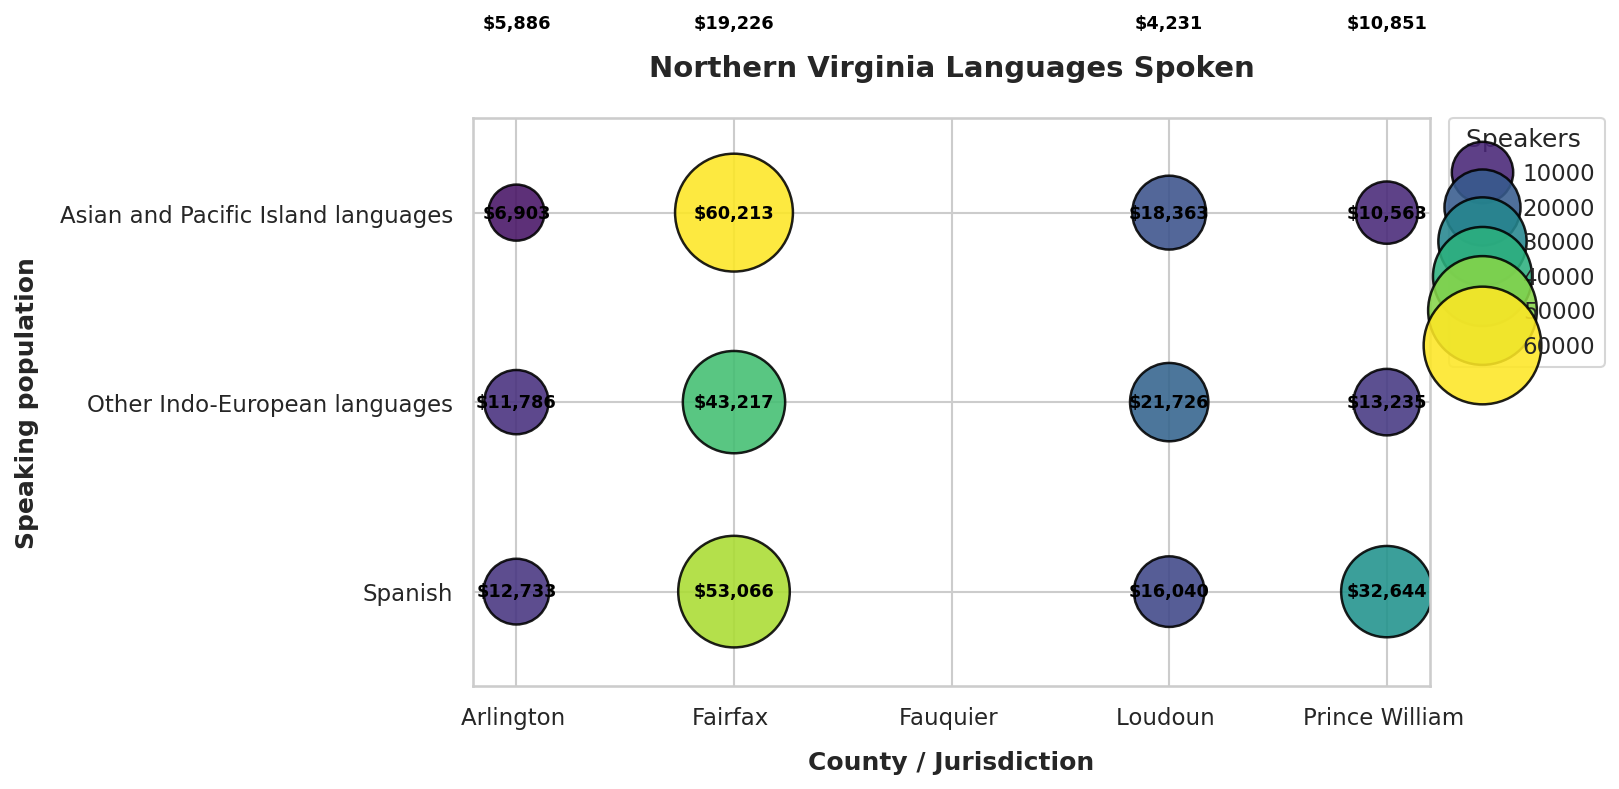

In [117]:
# Plot

sns.set_theme(style="whitegrid")
fig,ax = plt.subplots(figsize = (11,5.5),dpi = 150)

scatter = sns.scatterplot(
    data = df_speaking_language_clean_var,
    x = "Region",
    y = "Languages",
    size = "Speakers",
    hue = "Speakers",
    palette = "viridis",
    sizes = (600,3200),
    edgecolor="black",
    linewidth=1.2,
    alpha=0.88,
    ax=ax,
)

# Add the exact Speakers in each bubble

for _,row in df_speaking_language_clean_var.iterrows():
  if pd.notna(row["Speakers"]):
    ax.text(
        x = row["Region"],
        y = row["Languages"],
        s = f"${int(row["Speakers"]):,}",
        ha="center",
              va="center",
              fontsize=8.5,
              fontweight="bold",
              color="black",
  )

# Polish Titles and Axes
plt.title(
    "Northern Virginia Languages Spoken",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("County / Jurisdiction", fontweight="bold", labelpad=10)
plt.ylabel("Speaking population", fontweight="bold", labelpad=10)
ax.set_ylim(-0.5, 2.5)  # Add breathing room for top and bottom bubbles

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
    title="Speakers ",
)

plt.tight_layout()
plt.show()